# 02 — Research-led features: do they beat the engagement baseline?

**Question:** stage 1 showed that a descriptive engagement score catches few withdrawals, and mostly *after* students have gone silent. Do features describing the *pattern* of engagement and assessment behaviour do better?

* **Features** (`src/eew/features.py`): level, regularity, recency, trajectory (change from the student's own earlier activity), cohort-relative versions, assessment behaviour (missed, late, scores old enough to be released) and study context. Demographics are never used.
* **Model:** logistic regression per prediction week, chosen for interpretability. Gradient boosting was tried and gave the same results.
* **Validation:** 5-fold cross-validation **grouped by module presentation**, so the model is never scored on a cohort it trained on.
* **Comparison:** the stronger stage 1 baseline (cumulative clicks), at the same 10% contact capacity. Differences come with **paired bootstrap 95% intervals** over presentations.
* **Leakage:** a unit test (`tests/test_features.py`) adds clicks and submissions on or after the cutoff and checks that no feature changes.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from eew.config import RESULTS_DIR, CONTACT_CAPACITY
from eew import features as F
from eew.experiments import run_stage2

FIG = pathlib.Path.cwd().parent / "docs" / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
res = run_stage2()  # about 20 seconds; also writes results/stage2_*.csv
met, diff, abl = res["metrics"], res["differences"], res["ablation"]
pd.Series({g: ", ".join(c) for g, c in F.FEATURE_GROUPS.items()}, name="features").to_frame()

,features
level,"log_clicks_last7, log_clicks_last14, log_click..."
regularity,"active_share, active_days_last14"
recency,"days_since_last_click, never_clicked"
trajectory,"traj_log_ratio, traj_slope4, has_trajectory"
relative,"pct_clicks_last14, pct_clicks_cum, pct_active_..."
assessment,"n_due, share_missed, share_late, mean_days_lat..."
context,"registered_days_before, studied_credits, num_o..."


## 1. Is the model better than the baseline?

Paired differences (model minus baseline) in precision and recall, in percentage points. An interval that excludes 0 means the model is reliably better.

In [2]:
d = diff.copy()
for c in ["d_precision", "d_precision_lo", "d_precision_hi", "d_recall", "d_recall_lo", "d_recall_hi"]:
    d[c] = (d[c] * 100).round(1)
d["precision gain (pp)"] = d.d_precision.astype(str) + " [" + d.d_precision_lo.astype(str) + ", " + d.d_precision_hi.astype(str) + "]"
d["recall gain (pp)"] = d.d_recall.astype(str) + " [" + d.d_recall_lo.astype(str) + ", " + d.d_recall_hi.astype(str) + "]"
d.pivot(index="week", columns="target", values=["precision gain (pp)", "recall gain (pp)"])

precision gain (pp)                    recall gain (pp)  \
target       needs_support     will_withdraw     needs_support   
week                                                             
2         -0.2 [-1.7, 1.3]   1.9 [-2.0, 4.9]  -0.0 [-0.4, 0.3]   
4           5.8 [3.1, 8.0]    6.2 [3.9, 8.5]    1.3 [0.7, 1.8]   
6           7.0 [4.7, 8.9]  10.2 [6.7, 13.7]    1.6 [1.2, 2.1]   
8          9.0 [7.1, 10.5]  10.6 [7.2, 14.2]    2.2 [1.7, 2.6]   
10        11.5 [9.3, 13.6]  10.4 [7.9, 12.8]    2.8 [2.2, 3.5]   
12        11.2 [8.9, 13.6]  10.6 [7.8, 13.4]    2.8 [2.1, 3.6]   

                         
target    will_withdraw  
week                     
2       1.0 [-1.0, 2.5]  
4        3.4 [2.2, 4.6]  
6        6.1 [4.3, 7.9]  
8        7.0 [5.1, 8.9]  
10       7.6 [6.4, 8.9]  
12       8.5 [7.0, 9.9]

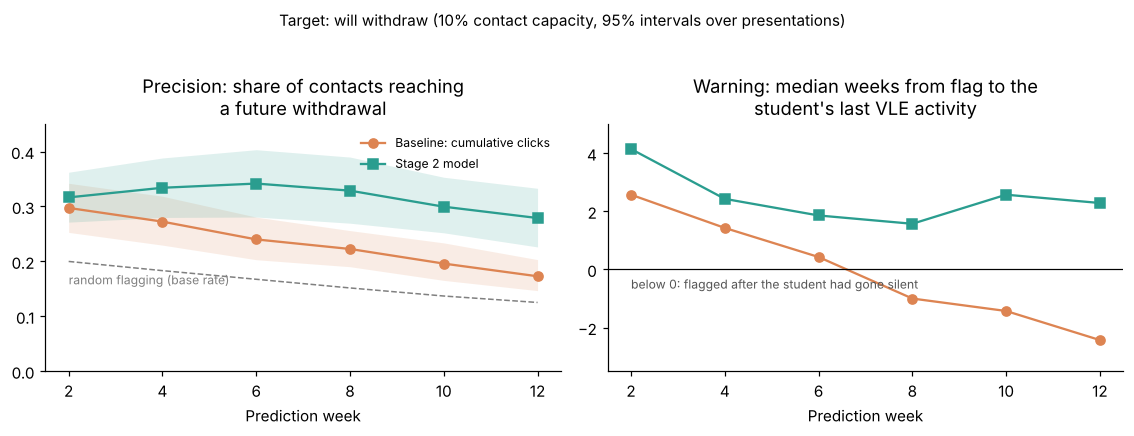

In [3]:
w = met[met.target == "will_withdraw"]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
styles = {"Baseline: cumulative clicks": ("#DD8452", "o"), "Stage 2 model": ("#2a9d8f", "s")}
for name, (c, mk) in styles.items():
    r = w[w.score == name]
    axes[0].plot(r.week, r.precision, marker=mk, color=c, label=name)
    axes[0].fill_between(r.week, r.precision_lo, r.precision_hi, color=c, alpha=0.15, lw=0)
    axes[1].plot(r.week, r.median_weeks_to_last_activity, marker=mk, color=c, label=name)
r = w[w.score == "Stage 2 model"]
axes[0].plot(r.week, r.base_rate, ls="--", color="grey", lw=1)
axes[0].text(2, r.base_rate.iloc[0] - 0.02, "random flagging (base rate)", color="grey", fontsize=8, va="top")
axes[0].set(title="Precision: share of contacts reaching\na future withdrawal", xlabel="Prediction week", ylim=(0, 0.45))
axes[0].legend(frameon=False, fontsize=8, loc="upper right")
axes[1].axhline(0, color="black", lw=0.8)
axes[1].text(2, -0.25, "below 0: flagged after the student had gone silent", fontsize=8, color="#555", va="top")
axes[1].set(title="Warning: median weeks from flag to the\nstudent's last VLE activity", xlabel="Prediction week", ylim=(-3.5, 5))
fig.suptitle("Target: will withdraw (10% contact capacity, 95% intervals over presentations)", y=1.03, fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "stage2_vs_baseline.png", bbox_inches="tight"); plt.show()

In [4]:
cols = ["precision", "recall", "auc", "median_weeks_to_withdrawal", "median_weeks_to_last_activity", "share_caught_already_inactive"]
met.set_index(["target", "week", "score"])[cols].round(3)

precision  recall    auc  \
target        week score                                                   
will_withdraw 2    Baseline: cumulative clicks      0.297   0.149  0.598   
                   Stage 2 model                    0.317   0.159  0.609   
needs_support 2    Baseline: cumulative clicks      0.756   0.168  0.683   
                   Stage 2 model                    0.753   0.168  0.691   
will_withdraw 4    Baseline: cumulative clicks      0.272   0.149  0.597   
                   Stage 2 model                    0.334   0.183  0.664   
needs_support 4    Baseline: cumulative clicks      0.797   0.182  0.693   
                   Stage 2 model                    0.854   0.195  0.724   
will_withdraw 6    Baseline: cumulative clicks      0.240   0.144  0.598   
                   Stage 2 model                    0.342   0.205  0.675   
needs_support 6    Baseline: cumulative clicks      0.811   0.190  0.705   
                   Stage 2 model                    0.880   0.206  0.753   
will_withdraw 8    Baseline: cumulative clicks      0.223   0.147  0.600   
                   Stage 2 model                    0.329   0.218  0.690   
needs_support 8    Baseline: cumulative clicks      0.833   0.200  0.717   
                   Stage 2 model                    0.922   0.221  0.780   
will_withdraw 10   Baseline: cumulative clicks      0.196   0.144  0.597   
                   Stage 2 model                    0.300   0.219  0.700   
needs_support 10   Baseline: cumulative clicks      0.846   0.208  0.725   
                   Stage 2 model                    0.961   0.236  0.815   
will_withdraw 12   Baseline: cumulative clicks      0.173   0.139  0.598   
                   Stage 2 model                    0.279   0.224  0.701   
needs_support 12   Baseline: cumulative clicks      0.847   0.212  0.733   
                   Stage 2 model                    0.959   0.241  0.824   

                                                median_weeks_to_withdrawal  \
target        week score                                                     
will_withdraw 2    Baseline: cumulative clicks                       8.857   
                   Stage 2 model                                     8.857   
needs_support 2    Baseline: cumulative clicks                       8.857   
                   Stage 2 model                                     9.286   
will_withdraw 4    Baseline: cumulative clicks                       9.571   
                   Stage 2 model                                     8.286   
needs_support 4    Baseline: cumulative clicks                       9.571   
                   Stage 2 model                                     7.429   
will_withdraw 6    Baseline: cumulative clicks                       9.714   
                   Stage 2 model                                     7.714   
needs_support 6    Baseline: cumulative clicks                       9.714   
                   Stage 2 model                                     7.429   
will_withdraw 8    Baseline: cumulative clicks                       9.429   
                   Stage 2 model                                     7.429   
needs_support 8    Baseline: cumulative clicks                       9.429   
                   Stage 2 model                                     7.286   
will_withdraw 10   Baseline: cumulative clicks                       9.429   
                   Stage 2 model                                     7.857   
needs_support 10   Baseline: cumulative clicks                       9.429   
                   Stage 2 model                                     7.714   
will_withdraw 12   Baseline: cumulative clicks                       8.714   
                   Stage 2 model                                     7.857   
needs_support 12   Baseline: cumulative clicks                       8.714   
                   Stage 2 model                                     6.857   

                                          

## 2. Which feature groups do the work?

Drop-one-group ablation for the withdrawal target: the loss in cross-validated AUC when a group is removed and the model refitted. Groups overlap (for example, level and cohort-relative level), so a small loss can mean a group is *redundant*, not useless. Coefficients are not shown, because correlated features make them unstable.

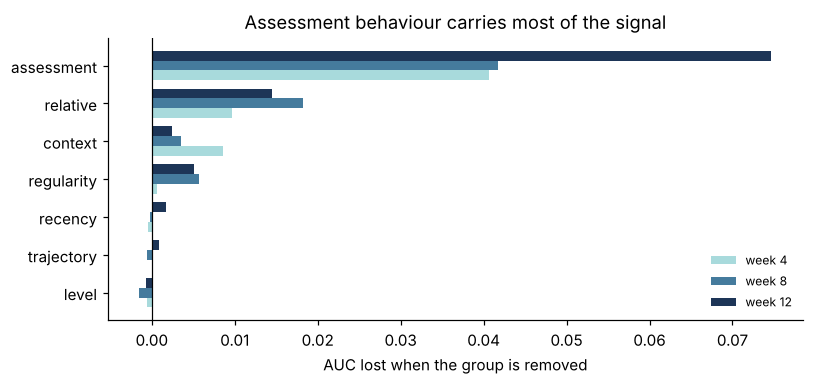

week,4,8,12
dropped_group,,,
level,-0.0006,-0.0015,-0.0007
trajectory,0.0001,-0.0006,0.0009
recency,-0.0004,-0.0003,0.0017
regularity,0.0006,0.0057,0.0051
context,0.0086,0.0036,0.0025
relative,0.0097,0.0183,0.0145
assessment,0.0407,0.0418,0.0747


In [5]:
piv = abl.pivot(index="dropped_group", columns="week", values="auc_loss")
piv = piv.loc[piv.mean(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(7.5, 3.6))
y = np.arange(len(piv))
for i, (wk, c) in enumerate(zip(piv.columns, ["#a8dadc", "#457b9d", "#1d3557"])):
    ax.barh(y + (i - 1) * 0.26, piv[wk], height=0.26, color=c, label=f"week {wk}")
ax.set_yticks(y, piv.index); ax.axvline(0, color="black", lw=0.8)
ax.set(xlabel="AUC lost when the group is removed", title="Assessment behaviour carries most of the signal")
ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout(); fig.savefig(FIG / "stage2_ablation.png", bbox_inches="tight"); plt.show()
piv.round(4)

## 3. Findings

1. **The model reliably beats the baseline from week 4 onwards.** At 10% capacity, precision for future withdrawals rises by 6–11 percentage points (paired 95% intervals exclude zero from week 4). It reaches 0.33–0.34 at weeks 4–8, against 0.22–0.27 for the baseline. AUC rises from about 0.60 to 0.66–0.70. At week 2 there is not yet enough behaviour to beat the baseline reliably.
2. **Flags now come before students go silent.** The median flag comes 1.6–2.6 weeks before a withdrawing student's last VLE activity, where the baseline flagged after it (−1 to −2.4 weeks) from week 8 on. The share of caught students already silent at flag time falls from about 54% to 34–38%.
3. **Assessment behaviour is the strongest signal.** Missed and late submissions and released scores account for most of the gain (AUC loss 0.04–0.075 when removed). Cohort-relative engagement comes second.
4. **The "drop from own baseline" hypothesis was not supported.** Trajectory and recency features add nothing measurable once level, regularity and assessment behaviour are included. They are kept for stage 3, where withdrawal timing is modelled directly, but the claim is not made here.
5. **For the broader *fail or withdraw* target,** precision reaches 0.85–0.96. But most of those catches are students who have already disengaged, so high precision there does not mean early warning.

**Limitations:** one model per week, not yet a single model of *when* withdrawal happens (stage 3); scores assume release within 14 days of submission; folds keep presentations apart but share module identity (unseen-module tests are stage 6).